In [ ]:
getwd()
list.files("/content")

[1] "/content"

[1] "sample_data"

In [ ]:
list.files("/", pattern = "processed.cleveland.data")

[1] "processed.cleveland.data"

In [ ]:
heart_data <- read.csv(
  "/processed.cleveland.data",
  header = FALSE,
  na.strings = "?"
)

colnames(heart_data) <- c(
  "age",
  "sex",
  "cp",
  "trestbps",
  "chol",
  "fbs",
  "restecg",
  "thalach",
  "exang",
  "oldpeak",
  "slope",
  "ca",
  "thal",
  "target"
)

head(heart_data)
dim(heart_data)
str(heart_data)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
2,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
3,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
4,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
5,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0
6,56,1,2,120,236,0,0,178,0,0.8,1,0,3,0


[1] 303  14

'data.frame':	303 obs. of  14 variables:
 $ age     : num  63 67 67 37 41 56 62 57 63 53 ...
 $ sex     : num  1 1 1 1 0 1 0 0 1 1 ...
 $ cp      : num  1 4 4 3 2 2 4 4 4 4 ...
 $ trestbps: num  145 160 120 130 130 120 140 120 130 140 ...
 $ chol    : num  233 286 229 250 204 236 268 354 254 203 ...
 $ fbs     : num  1 0 0 0 0 0 0 0 0 1 ...
 $ restecg : num  2 2 2 0 2 0 2 0 2 2 ...
 $ thalach : num  150 108 129 187 172 178 160 163 147 155 ...
 $ exang   : num  0 1 1 0 0 0 0 1 0 1 ...
 $ oldpeak : num  2.3 1.5 2.6 3.5 1.4 0.8 3.6 0.6 1.4 3.1 ...
 $ slope   : num  3 2 2 3 1 1 3 1 2 3 ...
 $ ca      : num  0 3 2 0 0 0 2 0 1 0 ...
 $ thal    : num  6 3 7 3 3 3 3 3 7 7 ...
 $ target  : int  0 2 1 0 0 0 3 0 2 1 ...


In [ ]:
# STEP 2: Deliberately introduce data-entry errors

# Negative BP values
heart_data$trestbps[1] <- -20
heart_data$trestbps[2] <- -10

# Missing BP values
heart_data$trestbps[3] <- NA
heart_data$trestbps[4] <- NA

# Extreme BP values greater than 300
heart_data$trestbps[5] <- 350
heart_data$trestbps[6] <- 400

# Display the modified values
heart_data$trestbps[1:10]

[1] -20 -10  NA  NA 350 400 140 120 130 140

In [ ]:
# STEP 3: Custom Blood Pressure Cleaning Function

clean_bp <- function(bp) {

  if (is.na(bp)) {
    return(NA)

  } else if (bp < 0) {
    return(NA)

  } else if (bp > 250) {
    return(250)

  } else {
    return(bp)
  }
}

In [ ]:
# Test the cleaning function

cat("Negative BP:", clean_bp(-20), "\n")
cat("Missing BP:", clean_bp(NA), "\n")
cat("Extreme BP:", clean_bp(350), "\n")
cat("Valid BP:", clean_bp(120), "\n")

Negative BP: NA 
Missing BP: NA 
Extreme BP: 250 
Valid BP: 120 


In [ ]:
# Apply the custom function to the entire BP column

heart_data$trestbps_clean <- sapply(
  heart_data$trestbps,
  clean_bp
)

# Compare original and cleaned values
data.frame(
  Original = heart_data$trestbps[1:10],
  Cleaned = heart_data$trestbps_clean[1:10]
)

Original,Cleaned
<dbl>,<dbl>
-20,NA
-10,NA
NA,NA
NA,NA
350,250
400,250
140,140
120,120
130,130


In [ ]:
# STEP 4: Error Handling using tryCatch()

safe_mean_bp <- function(bp) {

  tryCatch(
    {
      mean(bp, na.rm = TRUE)
    },
    warning = function(w) {
      message("Warning: ", w$message)
      NA
    },
    error = function(e) {
      message("Error: ", e$message)
      NA
    }
  )
}

# Calculate mean of cleaned BP
mean_bp <- safe_mean_bp(heart_data$trestbps_clean)

cat("Mean Blood Pressure:", mean_bp, "\n")

Mean Blood Pressure: 132.4314 


In [ ]:
# Safe Cholesterol / Blood Pressure Ratio

safe_ratio <- function(chol, bp) {

  tryCatch(
    {
      if (is.na(bp)) {
        stop("Blood pressure is missing.")
      }

      if (bp == 0) {
        stop("Blood pressure cannot be zero.")
      }

      if (bp < 0) {
        stop("Blood pressure cannot be negative.")
      }

      chol / bp
    },
    error = function(e) {
      message("Ratio Error: ", e$message)
      NA
    }
  )
}

In [ ]:
# Test valid BP
cat("Valid ratio:", safe_ratio(200, 120), "\n")

# Test missing BP
cat("Missing BP:", safe_ratio(200, NA), "\n")

# Test zero BP
cat("Zero BP:", safe_ratio(200, 0), "\n")

# Test negative BP
cat("Negative BP:", safe_ratio(200, -20), "\n")

Valid ratio: 1.666667 


Ratio Error: Blood pressure is missing.



Missing BP: NA 


Ratio Error: Blood pressure cannot be zero.



Zero BP: NA 


Ratio Error: Blood pressure cannot be negative.



Negative BP: NA 


In [ ]:
# STEP 5: Cleaning using a FOR LOOP

bp_loop <- heart_data$trestbps

loop_time <- system.time({

  for (i in seq_along(bp_loop)) {

    if (is.na(bp_loop[i])) {
      next

    } else if (bp_loop[i] < 0) {
      bp_loop[i] <- NA

    } else if (bp_loop[i] > 250) {
      bp_loop[i] <- 250
    }
  }
})

cat("For-loop execution time:\n")
print(loop_time)

For-loop execution time:
   user  system elapsed 
  0.007   0.000   0.007 


In [ ]:
# STEP 6: Cleaning using Vectorized Operations

bp_vectorized <- heart_data$trestbps

vectorized_time <- system.time({

  # Replace negative BP values with NA
  bp_vectorized[bp_vectorized < 0] <- NA

  # Cap BP values greater than 250 at 250
  bp_vectorized[bp_vectorized > 250] <- 250
})

cat("Vectorized execution time:\n")
print(vectorized_time)

Vectorized execution time:
   user  system elapsed 
  0.000   0.000   0.001 


In [ ]:
# STEP 7: Compare Execution Times

comparison <- data.frame(
  Method = c("For Loop", "Vectorized"),
  User_Time = c(
    loop_time["user.self"],
    vectorized_time["user.self"]
  ),
  System_Time = c(
    loop_time["sys.self"],
    vectorized_time["sys.self"]
  ),
  Elapsed_Time = c(
    loop_time["elapsed"],
    vectorized_time["elapsed"]
  )
)

comparison

Method,User_Time,System_Time,Elapsed_Time
<chr>,<dbl>,<dbl>,<dbl>
For Loop,0.007,0,0.007
Vectorized,0.000,0,0.001


In [ ]:
# Verify that both methods give the same result

identical(bp_loop, bp_vectorized)

[1] TRUE

In [ ]:
# STEP 9: Final Validation of Cleaned BP Data

# Use the vectorized cleaned data as the final BP column
heart_data$trestbps <- bp_vectorized

# Validation results
cat("===== FINAL BP VALIDATION =====\n")

cat("Missing BP values:",
    sum(is.na(heart_data$trestbps)), "\n")

cat("Minimum BP:",
    min(heart_data$trestbps, na.rm = TRUE), "\n")

cat("Maximum BP:",
    max(heart_data$trestbps, na.rm = TRUE), "\n")

cat("Mean BP:",
    mean(heart_data$trestbps, na.rm = TRUE), "\n")

cat("Median BP:",
    median(heart_data$trestbps, na.rm = TRUE), "\n")

cat("Negative BP values remaining:",
    sum(heart_data$trestbps < 0, na.rm = TRUE), "\n")

cat("BP values greater than 250 remaining:",
    sum(heart_data$trestbps > 250, na.rm = TRUE), "\n")

===== FINAL BP VALIDATION =====
Missing BP values: 4 
Minimum BP: 94 
Maximum BP: 250 
Mean BP: 132.4314 
Median BP: 130 
Negative BP values remaining: 0 
BP values greater than 250 remaining: 0 


In [ ]:
# STEP 10: Export Cleaned Dataset

write.csv(
  heart_data,
  "cleaned_heart_data.csv",
  row.names = FALSE
)

cat("cleaned_heart_data.csv created successfully!\n")

cleaned_heart_data.csv created successfully!


## Lab 3 Conclusion

The UCI Heart Disease dataset was cleaned using control-flow techniques in R. Deliberate data-entry errors were introduced into the trestbps variable, including negative values, missing values, and extreme values greater than 300.

A custom if-else function was implemented to convert negative blood pressure values to NA and cap values greater than 250 at 250. tryCatch() was used for safe mean calculation and for handling invalid cases while calculating the cholesterol-to-blood-pressure ratio.

The BP cleaning operation was implemented using both a for loop and vectorized operations. Their execution times were compared using system.time(). Both approaches produced the same cleaned results, while vectorized operations were more efficient for this cleaning task.

Final validation confirmed that no negative BP values and no BP values greater than 250 remained in the cleaned dataset.

# Lab 4 — Data Cleaning with Missing Values

## Aim
To identify and handle missing values in the Adult/Census Income dataset using R.

In [1]:
# STEP 1: Install and load required packages

install.packages("naniar")
install.packages("skimr")

library(naniar)
library(skimr)

cat("Packages loaded successfully!\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘gridExtra’, ‘plyr’, ‘norm’, ‘visdat’, ‘viridis’, ‘UpSetR’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘skimr’


The following object is masked from ‘package:naniar’:

    n_complete




Packages loaded successfully!


In [2]:
# STEP 2: Download UCI Adult Dataset

adult_url <- "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

download.file(
  adult_url,
  "adult.data",
  mode = "wb"
)

cat("Adult dataset downloaded successfully!\n")

Adult dataset downloaded successfully!


In [3]:
# Load Adult dataset

adult_data <- read.csv(
  "adult.data",
  header = FALSE,
  na.strings = "?",
  strip.white = TRUE
)

# Add column names
colnames(adult_data) <- c(
  "age",
  "workclass",
  "fnlwgt",
  "education",
  "education_num",
  "marital_status",
  "occupation",
  "relationship",
  "race",
  "sex",
  "capital_gain",
  "capital_loss",
  "hours_per_week",
  "native_country",
  "income"
)

cat("Adult dataset loaded successfully!\n")

dim(adult_data)
head(adult_data)

Adult dataset loaded successfully!


[1] 32561    15

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
,<int>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<int>,<int>,<chr>,<chr>
1,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
2,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
3,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
4,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
5,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
6,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K


In [4]:
# STEP 3: Introduce different types of missing and invalid data

# Make a copy so the original loaded dataset remains available
adult_dirty <- adult_data

# 1. Introduce NA
adult_dirty$age[1] <- NA

# 2. Introduce a blank string
adult_dirty$workclass[2] <- ""

# 3. Introduce NaN
adult_dirty$age[3] <- NaN

# 4. Introduce an impossible numeric value
adult_dirty$age[4] <- 999

cat("Missing/invalid values introduced successfully!\n")

# Display affected rows
adult_dirty[1:4, c("age", "workclass")]

Missing/invalid values introduced successfully!


,age,workclass
,<dbl>,<chr>
1,NA,State-gov
2,50,
3,NaN,Private
4,999,Private


In [5]:
# STEP 4: Detect different forms of missing/invalid data

cat("===== NA DETECTION =====\n")
cat("Number of NA values:",
    sum(is.na(adult_dirty)), "\n\n")

cat("===== NaN DETECTION =====\n")
cat("Number of NaN values:",
    sum(is.nan(adult_dirty$age)), "\n\n")

cat("===== NULL DEMONSTRATION =====\n")

x <- NULL

cat("Is x NULL?",
    is.null(x), "\n")

cat("===== BLANK STRING DETECTION =====\n")

cat("Blank workclass values:",
    sum(adult_dirty$workclass == "", na.rm = TRUE), "\n\n")

cat("===== IMPOSSIBLE AGE DETECTION =====\n")

cat("Age values equal to 999:",
    sum(adult_dirty$age == 999, na.rm = TRUE), "\n")

===== NA DETECTION =====
Number of NA values: 4264 

===== NaN DETECTION =====
Number of NaN values: 1 

===== NULL DEMONSTRATION =====
Is x NULL? TRUE 
===== BLANK STRING DETECTION =====
Blank workclass values: 1 

===== IMPOSSIBLE AGE DETECTION =====
Age values equal to 999: 1 


In [6]:
# STEP 5: Missing-value summary using naniar

cat("===== MISSING VALUE SUMMARY =====\n")

miss_summary <- miss_var_summary(adult_dirty)

print(miss_summary)

===== MISSING VALUE SUMMARY =====
# A tibble: 15 × 3
   variable       n_miss pct_miss
   <chr>           <int>    <num>
 1 occupation       1843  5.66   
 2 workclass        1836  5.64   
 3 native_country    583  1.79   
 4 age                 2  0.00614
 5 fnlwgt              0  0      
 6 education           0  0      
 7 education_num       0  0      
 8 marital_status      0  0      
 9 relationship        0  0      
10 race                0  0      
11 sex                 0  0      
12 capital_gain        0  0      
13 capital_loss        0  0      
14 hours_per_week      0  0      
15 income              0  0      


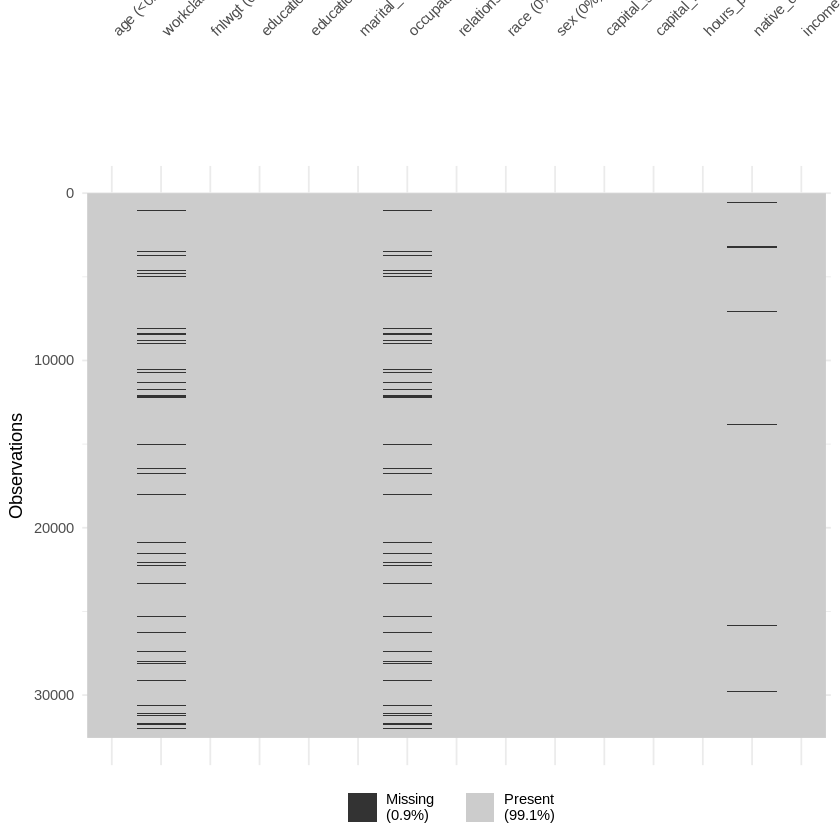

In [7]:
# STEP 6: Visualize missing values

vis_miss(adult_dirty)

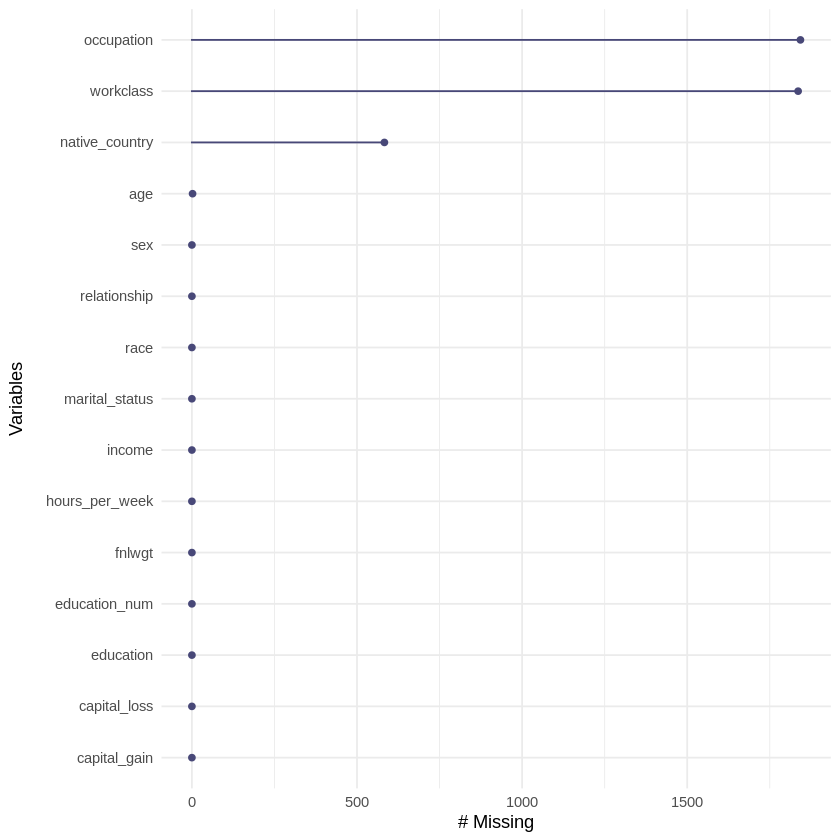

In [8]:
# Missing values by variable

gg_miss_var(adult_dirty)

In [9]:
# STEP 7A: Convert invalid values and blank strings

clean_adult <- adult_dirty

# Convert impossible age value to NA
clean_adult$age[clean_adult$age < 0 | clean_adult$age > 100] <- NA

# Replace blank categorical values with "Unknown"
clean_adult$workclass[
  is.na(clean_adult$workclass) | clean_adult$workclass == ""
] <- "Unknown"

cat("Invalid age values converted to NA.\n")
cat("Blank workclass values replaced with 'Unknown'.\n")

Invalid age values converted to NA.
Blank workclass values replaced with 'Unknown'.


In [10]:
# STEP 7B: Custom median imputation function

median_impute <- function(x) {

  # Calculate median using only valid values
  med <- median(x, na.rm = TRUE)

  # Replace NA and NaN with median
  x[is.na(x) | is.nan(x)] <- med

  return(x)
}

cat("Median imputation function created successfully.\n")

Median imputation function created successfully.


In [11]:
# STEP 7C: Impute missing numeric values

numeric_columns <- c(
  "age",
  "fnlwgt",
  "education_num",
  "capital_gain",
  "capital_loss",
  "hours_per_week"
)

for (col in numeric_columns) {
  clean_adult[[col]] <- median_impute(clean_adult[[col]])
}

cat("Median imputation completed for selected numeric variables.\n")

Median imputation completed for selected numeric variables.


In [12]:
# STEP 7D: Identify complete and incomplete observations

complete_rows <- complete.cases(clean_adult)

cat("Total observations:", nrow(clean_adult), "\n")
cat("Complete observations:", sum(complete_rows), "\n")
cat("Incomplete observations:", sum(!complete_rows), "\n")

Total observations: 32561 
Complete observations: 30162 
Incomplete observations: 2399 


In [13]:
# STEP 8A: Missing values BEFORE cleaning

total_values_before <- nrow(adult_dirty) * ncol(adult_dirty)

missing_before <- sum(is.na(adult_dirty))

missing_percentage_before <-
  (missing_before / total_values_before) * 100

cat("===== BEFORE CLEANING =====\n")
cat("Total values:", total_values_before, "\n")
cat("Missing values:", missing_before, "\n")
cat("Missing percentage:",
    round(missing_percentage_before, 2), "%\n")

===== BEFORE CLEANING =====
Total values: 488415 
Missing values: 4264 
Missing percentage: 0.87 %


In [14]:
# STEP 8B: Missing values AFTER cleaning

total_values_after <- nrow(clean_adult) * ncol(clean_adult)

missing_after <- sum(is.na(clean_adult))

missing_percentage_after <-
  (missing_after / total_values_after) * 100

cat("===== AFTER CLEANING =====\n")
cat("Total values:", total_values_after, "\n")
cat("Missing values:", missing_after, "\n")
cat("Missing percentage:",
    round(missing_percentage_after, 2), "%\n")

===== AFTER CLEANING =====
Total values: 488415 
Missing values: 2426 
Missing percentage: 0.5 %


In [15]:
# STEP 8C: Before vs After comparison

missing_comparison <- data.frame(
  Stage = c("Before Cleaning", "After Cleaning"),
  Missing_Values = c(
    missing_before,
    missing_after
  ),
  Missing_Percentage = c(
    round(missing_percentage_before, 2),
    round(missing_percentage_after, 2)
  )
)

missing_comparison

Stage,Missing_Values,Missing_Percentage
<chr>,<int>,<dbl>
Before Cleaning,4264,0.87
After Cleaning,2426,0.50


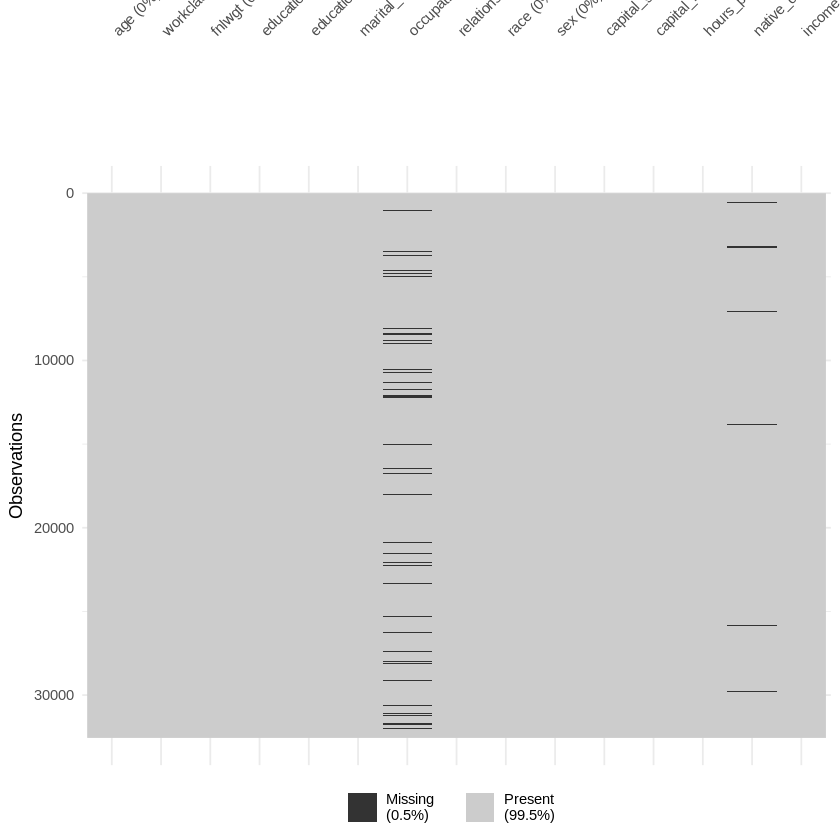

In [16]:
# STEP 8D: Missingness visualization AFTER cleaning

vis_miss(clean_adult)

In [17]:
# STEP 9: Final validation using skimr

skim(clean_adult)

,skim_type,skim_variable,n_missing,complete_rate,character.min,character.max,character.empty,character.n_unique,character.whitespace,numeric.mean,numeric.sd,numeric.p0,numeric.p25,numeric.p50,numeric.p75,numeric.p100,numeric.hist
,<chr>,<chr>,<int>,<dbl>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,character,workclass,0,1.0000000,7,16,0,9,0,NA,NA,NA,NA,NA,NA,NA,NA
2,character,education,0,1.0000000,3,12,0,16,0,NA,NA,NA,NA,NA,NA,NA,NA
3,character,marital_status,0,1.0000000,7,21,0,7,0,NA,NA,NA,NA,NA,NA,NA,NA
4,character,occupation,1843,0.9433985,5,17,0,14,0,NA,NA,NA,NA,NA,NA,NA,NA
5,character,relationship,0,1.0000000,4,14,0,6,0,NA,NA,NA,NA,NA,NA,NA,NA
6,character,race,0,1.0000000,5,18,0,5,0,NA,NA,NA,NA,NA,NA,NA,NA
7,character,sex,0,1.0000000,4,6,0,2,0,NA,NA,NA,NA,NA,NA,NA,NA
8,character,native_country,583,0.9820951,4,26,0,41,0,NA,NA,NA,NA,NA,NA,NA,NA
9,character,income,0,1.0000000,4,5,0,2,0,NA,NA,NA,NA,NA,NA,NA,NA


In [18]:
# Final validation checks

cat("===== FINAL VALIDATION =====\n")

cat("Age values equal to 999:",
    sum(clean_adult$age == 999, na.rm = TRUE), "\n")

cat("Missing age values:",
    sum(is.na(clean_adult$age)), "\n")

cat("Blank workclass values:",
    sum(clean_adult$workclass == "", na.rm = TRUE), "\n")

cat("Unknown workclass values:",
    sum(clean_adult$workclass == "Unknown", na.rm = TRUE), "\n")

cat("Incomplete observations:",
    sum(!complete.cases(clean_adult)), "\n")

===== FINAL VALIDATION =====
Age values equal to 999: 0 
Missing age values: 0 
Blank workclass values: 0 
Unknown workclass values: 1837 
Incomplete observations: 2399 


In [19]:
# STEP 10: Export cleaned Adult dataset

write.csv(
  clean_adult,
  "cleaned_adult_data.csv",
  row.names = FALSE
)

cat("cleaned_adult_data.csv created successfully!\n")

cleaned_adult_data.csv created successfully!


## Lab 4 Conclusion

The Adult/Census Income dataset was analyzed for different types of missing and invalid values. NA, NaN, NULL, blank strings and an impossible age value were identified using appropriate R functions.

Missing values were summarized and visualized using the naniar package. Invalid age values were converted to NA, blank categorical values were replaced with "Unknown" and missing numeric values were handled using a custom median-imputation function. complete.cases() was used to identify incomplete observations.

The number and percentage of missing values before and after cleaning were compared. The cleaned dataset was validated using skimr::skim() and additional checks confirmed that impossible age values and blank categorical values were removed. The final cleaned dataset was exported as cleaned_adult_data.csv.